# Packed Bubble Chart (proportional symbols)

**Family:** Magnitude &nbsp;|&nbsp; **Library:** matplotlib / seaborn

> *Magnitude:* Compare sizes, relative or absolute (usually counts rather than rates).

## Design purpose

Circles sized by value and packed together without axes. It gives a quick, attractive impression of which items are big and which are small.

## When to use

- Show orders of magnitude when values differ greatly (large vs. small players)
- Editorial or overview graphics where precision is secondary

## Avoid when

- Values are close (people cannot compare circle areas precisely)
- Exact comparison or ranking is needed (use bars)

## Alternatives

- Treemap
- Horizontal bar chart

## Design tips

- Scale circle AREA, not radius, to the value; label the biggest bubbles directly

## Example

Market capitalisation of 15 (fictional) companies.

### Setup

In [1]:
%matplotlib inline
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Library style: categorical colors in fixed order, recessive axes, hairline grid.
PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100",
           "#e87ba4", "#008300", "#6250d6", "#e34948"]
SEQ_CMAP = "Blues"      # sequential: one hue, light -> dark
DIV_CMAP = "RdBu_r"     # diverging: two opposite hues, neutral midpoint
GRAY = "#b8b7b1"        # de-emphasised marks
plt.rcParams.update({
    "figure.figsize": (8, 4.8), "figure.dpi": 110, "figure.facecolor": "#fcfcfb",
    "axes.facecolor": "#fcfcfb", "axes.edgecolor": "#c9c8c3", "axes.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e6e5e1", "grid.linewidth": 0.6, "axes.axisbelow": True,
    "axes.prop_cycle": plt.cycler(color=PALETTE),
    "axes.titlesize": 13, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.labelcolor": "#52514e", "xtick.color": "#52514e", "ytick.color": "#52514e",
    "text.color": "#0b0b0b", "font.size": 10, "lines.linewidth": 2,
    "legend.frameon": False,
})

### Data

In [2]:
rng = np.random.default_rng(17)
df = pd.DataFrame({"company": [f"Co. {c}" for c in "ABCDEFGHIJKLMNO"],
                   "market_cap_bn": np.sort(rng.lognormal(4.5, 0.9, 15))[::-1].round()})
df["sector"] = ["Tech", "Tech", "Finance", "Health", "Tech", "Energy", "Finance", "Health",
                "Energy", "Tech", "Finance", "Health", "Energy", "Tech", "Finance"]
df.head()

,company,market_cap_bn,sector
0,Co. A,480.0,Tech
1,Co. B,243.0,Tech
2,Co. C,207.0,Finance
3,Co. D,153.0,Health
4,Co. E,122.0,Tech


### Plot

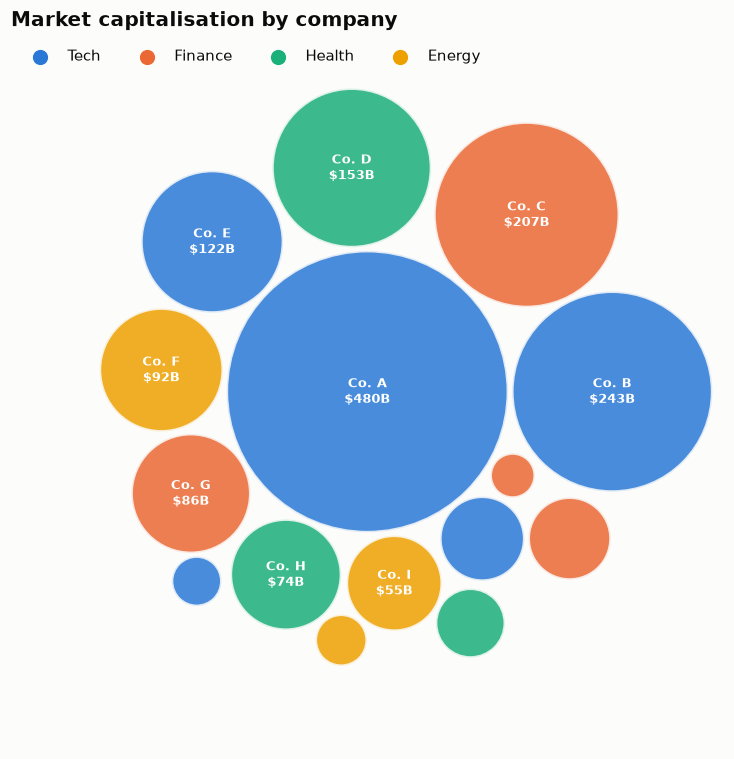

In [3]:
# simple greedy circle packing: place each circle as close to the center as possible
radii = np.sqrt(df["market_cap_bn"].values / np.pi)
placed = []
for r in radii:
    if not placed:
        placed.append((0.0, 0.0, r)); continue
    best = None
    for ang in np.linspace(0, 2 * np.pi, 180, endpoint=False):
        for dist in np.linspace(0, 60, 400):
            x, y = dist * np.cos(ang), dist * np.sin(ang)
            if all(np.hypot(x - px, y - py) >= r + pr + 0.3 for px, py, pr in placed):
                if best is None or dist < best[0]:
                    best = (dist, x, y)
                break
    placed.append((best[1], best[2], r))
sectors = list(dict.fromkeys(df["sector"]))
fig, ax = plt.subplots(figsize=(7, 7))
for (x, y, r), (_, row) in zip(placed, df.iterrows()):
    c = PALETTE[sectors.index(row["sector"])]
    ax.add_patch(plt.Circle((x, y), r, color=c, alpha=0.85, ec="#fcfcfb", lw=2))
    if r > 4:
        ax.text(x, y, f"{row['company']}\n${row['market_cap_bn']:.0f}B", ha="center",
                va="center", fontsize=8.5, color="white", fontweight="bold")
lim = max(abs(v) + r for x, y, r in placed for v in (x, y)) + 1
ax.set_xlim(-lim, lim); ax.set_ylim(-lim, lim)
ax.set_aspect("equal"); ax.axis("off")
for i, s in enumerate(sectors):
    ax.scatter([], [], color=PALETTE[i], s=80, label=s)
ax.legend(loc="upper left", bbox_to_anchor=(0, 1.0), ncol=4)
ax.set_title("Market capitalisation by company")
fig.tight_layout()
plt.show()

---
Standalone script: [`packed_bubbles.py`](packed_bubbles.py) &nbsp;·&nbsp; [Catalogue](../../README.md) &nbsp;·&nbsp; [Gallery](../../gallery/index.html)